## Example showing the computation of 
###   (1) distances from the coordinate file, 
###   (2) orientation factors, followed by 
###   (3) FRET rates


Shown sequentially below. 

-------------------------------------


In [1]:
import os.path
import numpy as np
import matplotlib.pyplot as plt
import math

--------------------------

In [2]:
## importing function from src folder

In [3]:
from src import get_distance as D

In [4]:
target_coord_file = 'resd_coord_file_sel.DAT'

------------------------

### Distance matrix

In [5]:
# use the predefined function which processes the DAT file

In [6]:
chl_res_ids, chl_coords, car_res_ids, car_coords = D.extract_distance(target_coord_file)

Num chl identified :  152
Num car identified :  34


In [7]:
# following code block computes the distance between the the two points in 3D-space

In [8]:
nCar = car_coords.shape[0]
nChl = chl_coords.shape[0]

dm = np.zeros((nCar, nChl))

for i in range(nCar):
    for j in range(nChl):
        
        coord1 = car_coords[i,:]
        coord2 = chl_coords[j,:]
        distance = math.sqrt( (coord2[0] - coord1[0])**2 + \
                             (coord2[1] - coord1[1])**2+ \
                             (coord2[2] - coord1[2])**2 ) 
        dm [i,j] = distance

In [9]:
dmT = dm.T # transpose

In [10]:
print(dmT.shape)

(152, 34)


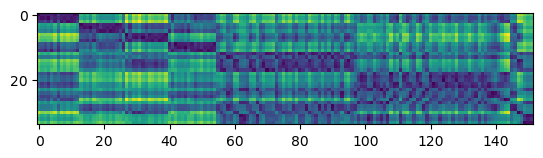

In [11]:
plt.imshow(dm)

In [12]:
# Optional: wrap into a pandas DataFrame for labeling
import pandas as pd


# df_dist is a dataframe

df_dist = pd.DataFrame(dm.T, index=chl_res_ids, columns=car_res_ids)
print(df_dist.shape)

(152, 34)


-------------------------------

# $\kappa^2$ : Orientation factor

In [13]:
from src import get_orientation as K

specific_file = 'resd_coord_file_sel.DAT'

In [14]:
# angles file is a specially designed file which
#   has information on the coordinate for
#   different transition dipole moments

ANGLES_FILE = "./theoretical_data/chl_data.txt"  
chl_tdm_label = "S4"  # pick TDM of interest
                      # (S1 : Qy)
                      # (S2 : Qx)
                      # (S3 : Bx)
                      # (S4 : By)

donor='chl'
acceptor='carS2'

# extracts IDs, coords and vectors
chl_ids, chl_coords, chl_vectors, car_ids, car_coords, car_vectors = K.extract_chl_car_vectors(specific_file, 
                                                                                             ANGLES_FILE, 
                                                                                             chl_tdm_label='S4')

# performs calculation
k2_matrix_S4 = K.compute_kappa2_matrix(chl_ids, chl_coords, chl_vectors, car_ids, car_coords, car_vectors)
print("kappa^2 matrix shape:", k2_matrix_S4.shape)


kappa^2 matrix shape: (152, 34)


-------------------------

# FRET RATES

In [15]:

###################################################################### 
# designed for pandas dataframes
# this function accepts kDF, distanceDF as dataframes and all others
#    as float args

def FRET_rate_inv_ps_vector2(
                            kDF,
                            distanceDF,
                            ref_index=None,
                            phiD_chla=None,
                            spec_overlapJ_chla=None,
                            tauD_chla=None,
                            phiD_chlb=None,
                            spec_overlapJ_chlb=None,
                            tauD_chlb=None
                            ):
    
    factor = 8.79e-5  # Equation 1 from  https://doi.org/10.1021/acsomega.3c05895

    # create empty DataFrame for results with same shape & index/columns
    result = pd.DataFrame(index=kDF.index, columns=kDF.columns, dtype=float)

    # iterate over rows
    for idx in kDF.index:
        #print(idx, type(idx))
        if idx.startswith("CHL"):
            # use CHL-b parameters
            phiD = phiD_chlb
            J = spec_overlapJ_chlb
            tauD = tauD_chlb
        else:
            # use CHL-a / default parameters
            phiD = phiD_chla
            J = spec_overlapJ_chla
            tauD = tauD_chla

        # calculate row-wise
        row_k = kDF.loc[idx]
        row_dist = distanceDF.loc[idx]
        numerator = row_k * phiD * J * (ref_index**-4) * (1 / (tauD * 1e-12))
        result.loc[idx] = (factor * numerator) / (row_dist**6)

    return result

###################################################################### 

----------------------

In [16]:
df_kappa_S4 = pd.DataFrame( k2_matrix_S4, index=chl_ids, columns=car_ids)


In [17]:
df_kappa_S4

,LUT314(1),XAT315(1),BCR316(1),LUT314(2),XAT315(2),BCR316(2),LUT614(3),XAT615(3),BCR616(3),LUT316(4),...,BCR303(F),BCR308(F),BCR106(G),BCR101(I),BCR104(J),BCR105(J),BCR201(L),BCR205(L),BCR206(L),BCR203(K)
CLA301(1),0.053087,1.365387,0.115222,1.308826,0.093404,1.859694,0.879936,0.243876,1.066861,1.806657,...,0.251871,0.289969,0.270641,1.996310,0.017304,0.027643,1.033457,2.408272,0.266380,0.345938
CLA302(1),0.691027,0.763085,0.043754,0.540386,0.214855,2.115142,0.308594,0.374392,1.666207,0.404423,...,0.599677,0.571251,0.037309,0.840317,1.873897,0.266789,0.259046,0.335950,0.790541,0.504446
CLA303(1),0.048903,2.282410,1.441837,0.000213,0.500081,0.161681,0.000794,0.535708,0.248677,0.002258,...,0.148025,0.442181,0.077515,1.516183,0.820107,0.235818,0.341077,3.218918,0.003176,0.923164
CLA304(1),0.078648,1.737161,0.313866,0.292905,0.293655,1.073589,0.249552,0.282795,1.076420,0.347947,...,0.065214,0.301043,0.015888,0.284756,0.964664,0.206599,0.003979,1.565425,0.245448,0.530210
CHL305(1),0.344136,3.176350,0.266653,0.897480,0.037169,1.757145,0.821286,0.025721,1.411619,0.876159,...,0.011454,0.136908,0.373493,0.277483,0.344904,0.079560,0.833778,0.004686,0.516107,0.006050
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
CLA202(L),0.927787,0.235449,0.295456,1.275235,0.449346,0.219413,0.784352,0.260067,0.092576,1.207121,...,0.968648,0.013173,1.389652,2.247918,0.583434,0.416924,1.284613,1.008712,0.988646,1.867134
CLA203(L),1.011804,0.018788,0.746163,1.154144,0.000039,0.440497,0.888742,0.005167,0.218333,1.157541,...,0.009542,0.251585,0.526802,1.182180,0.195221,0.002334,1.401922,0.250570,0.224828,1.516169
CLA204(L),0.920558,0.019400,0.186373,0.418203,0.000013,0.014442,0.017709,0.163410,0.062775,0.855649,...,0.336380,0.427846,2.315143,1.887513,0.001476,0.000068,0.170400,0.006304,0.726833,0.560680
CLA201(K),0.024574,1.385168,0.006408,0.500803,1.597790,0.314917,1.068967,1.300054,0.963012,0.150308,...,0.105316,1.243792,0.017543,0.145806,0.893676,0.724253,0.036291,0.278283,0.069109,0.750154


All required components are ready. 

---------------------


## Analysis for $B_y$ state as donor in chl

In [18]:
phiD = 9e-5         # fl yield
ref_index = 1.40      # unitless
tauD  =  0.162            # lifetime of the donor, in ps
#distance  =    df_dist   # in Angstrom
#orientation_factor = df_kappa (already squared)

---------------------------

In [19]:
FRET_k_DF_S4 = FRET_rate_inv_ps_vector2(
                                    df_kappa_S4,
                                    df_dist,
                                    ref_index = 1.40,
                                    # parameters for chl-a below
                                    phiD_chla = 9e-5,
                                    spec_overlapJ_chla = 4.00739e+15,
                                    tauD_chla = 0.162,
                                    # parameters for chl-b below
                                    phiD_chlb=0.92*1e-4,
                                    spec_overlapJ_chlb=4.25318e+15,
                                    tauD_chlb=0.162
                                    )

-----------------------

In [20]:
target = (1/FRET_k_DF_S4) * 1e+12   # get lifetimes in ps

target_chlS4_carS2 =  target

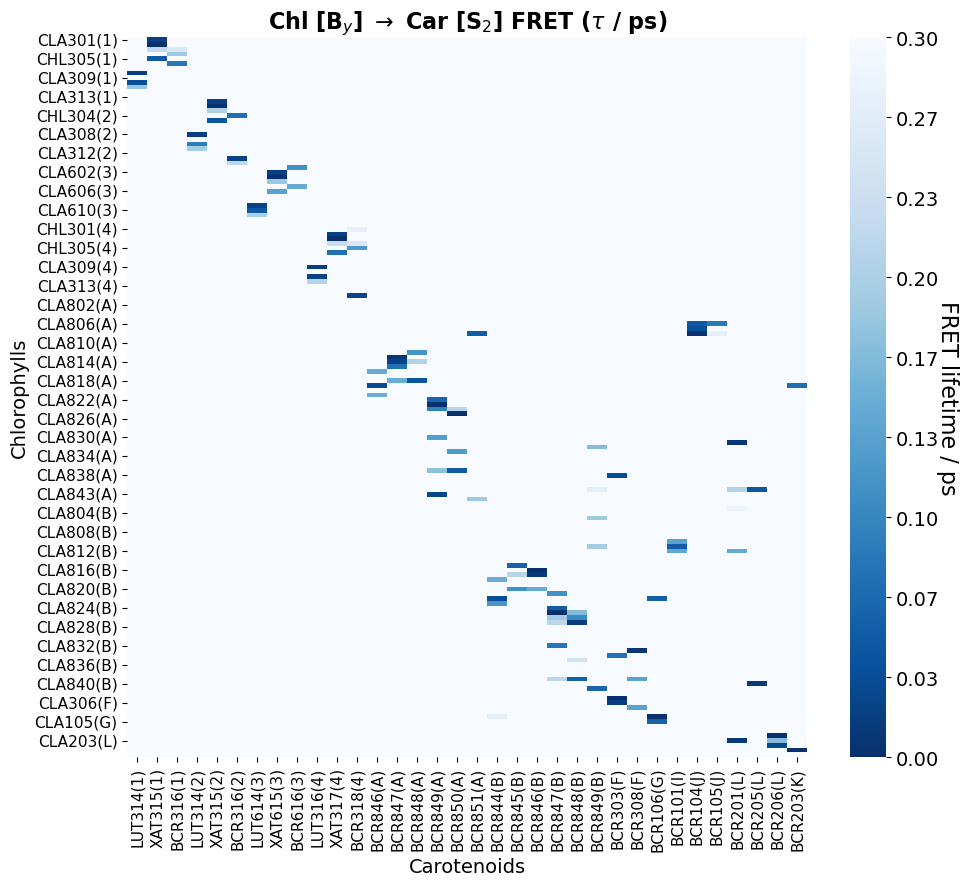

In [22]:
plt.rcParams.update({'font.size': 11})

import seaborn as sns
import matplotlib.colors as colors


chl_tdm_label = 'S4'
plt.figure(figsize=(10,9))

# Create reversed colormap for darker colors near zero
cmap_reversed = sns.color_palette("Blues_r", as_cmap=True)

# Extract min/max from data
vmin = target.min().min()
vmax = target.max().max()

ax = sns.heatmap(target, cmap=cmap_reversed, annot=False, vmin=0, vmax= 0.3 )

# Generate 5 evenly spaced ticks
ticks = np.linspace(0, 0.3, 10)

# Get colorbar and apply ticks
cbar = ax.collections[0].colorbar
cbar.set_ticks(ticks)
cbar.set_ticklabels([f"{t:.2f}" for t in ticks])
cbar.set_label(r'FRET lifetime / ps', rotation=270, labelpad=15, fontsize=16)
cbar.ax.tick_params(labelsize=14)

plt.xlabel("Carotenoids", fontsize=14)
plt.ylabel("Chlorophylls", fontsize=14)
chl_tdm_label = 'B'
title_str = 'Chl [' + chl_tdm_label + r'$_{y}$] $\rightarrow$ Car [S$_{2}$] FRET ($\tau$ / ps)' 
plt.title(title_str, fontweight='bold', fontsize=16)

#-----------------------------------------------------------------

plt.tight_layout()


In [ ]:
# above is an example showing the calculation for chl S4 to car S2 case

-------------------

## Analysis for $B_x$ state as donor in chl


In [ ]:
# angles file is a specially designed file which
#   has information on the coordinate for
#   different transition dipole moments

ANGLES_FILE = "./theoretical_data/chl_data.txt"  
chl_tdm_label = "S3"  # pick TDM of interest
                      # (S1 : Qy)
                      # (S2 : Qx)
                      # (S3 : Bx)
                      # (S4 : By)

donor='chl'
acceptor='carS2'

# extracts IDs, coords and vectors
chl_ids, chl_coords, chl_vectors, car_ids, car_coords, car_vectors = K.extract_chl_car_vectors(specific_file, 
                                                                                             ANGLES_FILE, 
                                                                                             chl_tdm_label='S3')

# performs calculation
k2_matrix_S3 = K.compute_kappa2_matrix(chl_ids, chl_coords, chl_vectors, car_ids, car_coords, car_vectors)
print("kappa^2 matrix shape:", k2_matrix_S3.shape)

df_kappa_S3 = pd.DataFrame( k2_matrix_S4, index=chl_ids, columns=car_ids)


FRET_k_DF_S3 = FRET_rate_inv_ps_vector2(
                                    df_kappa_S3,
                                    df_dist,
                                    ref_index = 1.40,
                                    # parameters for chl-a below
                                    phiD_chla = 9e-5,
                                    spec_overlapJ_chla = 4.00739e+15,
                                    tauD_chla = 0.162,
                                    # parameters for chl-b below
                                    phiD_chlb=0.92*1e-4,
                                    spec_overlapJ_chlb=4.25318e+15,
                                    tauD_chlb=0.162
                                    )

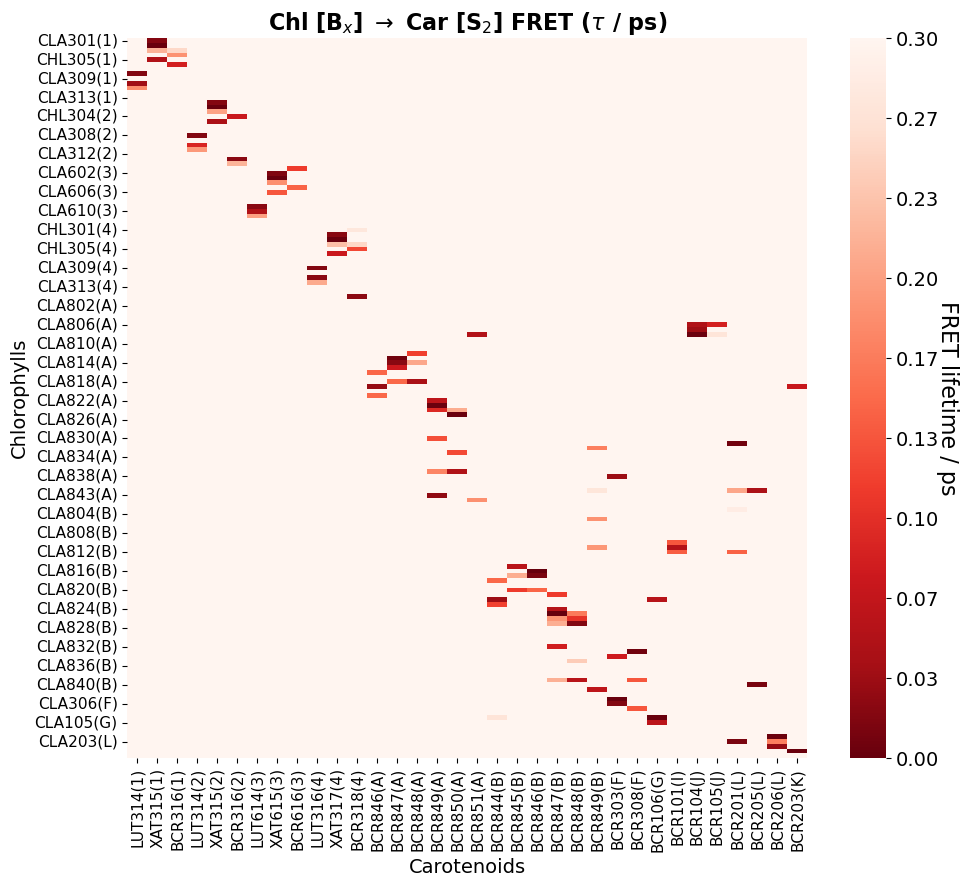

In [23]:
plt.rcParams.update({'font.size': 11})

import seaborn as sns
import matplotlib.colors as colors


chl_tdm_label = 'S3'
plt.figure(figsize=(10,9))

# Create reversed colormap for darker colors near zero
cmap_reversed = sns.color_palette("Reds_r", as_cmap=True)

# Extract min/max from data
vmin = target.min().min()
vmax = target.max().max()

ax = sns.heatmap(target, cmap=cmap_reversed, annot=False, vmin=0.0, vmax= 0.3 )

# Generate 5 evenly spaced ticks
ticks = np.linspace(0, 0.3, 10)

# Get colorbar and apply ticks
cbar = ax.collections[0].colorbar
cbar.set_ticks(ticks)
cbar.set_ticklabels([f"{t:.2f}" for t in ticks])
cbar.set_label(r'FRET lifetime / ps', rotation=270, labelpad=15, fontsize=16)
cbar.ax.tick_params(labelsize=14)

plt.xlabel("Carotenoids", fontsize=14)
plt.ylabel("Chlorophylls", fontsize=14)
chl_tdm_label = 'B'
title_str = 'Chl [' + chl_tdm_label + r'$_{x}$] $\rightarrow$ Car [S$_{2}$] FRET ($\tau$ / ps)' 
plt.title(title_str, fontweight='bold', fontsize=16)

#-----------------------------------------------------------------

plt.tight_layout()


----------------------------